ell = 614 m, 2*pi*ell = 3.86 km, tau = 4.21 days


/var/folders/kl/3mt9f4qs1559xwy3mr60s7980000gp/T/ipykernel_82374/3278104438.py:68: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax2.legend(fontsize=8)


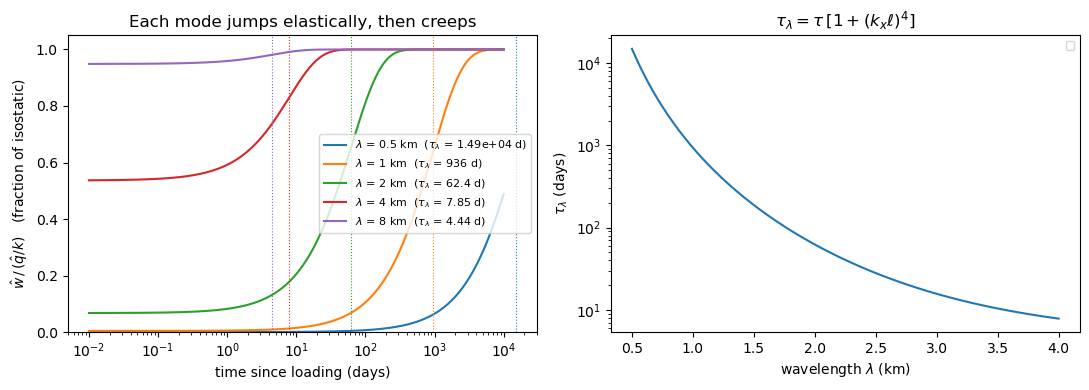

In [33]:
import numpy as np
import matplotlib.pyplot as plt

# --- parameters ---
H      = 250.0      # ice thickness (m)
E      = 1e9        # Young's modulus (Pa)
nu     = 0.3        # Poisson's ratio
eta    = 1e14       # viscosity (Pa s)
rho_sw = 1028.0     # seawater density (kg/m^3)
g      = 9.81       # gravity (m/s^2)
q_hat  = 1.0        # load amplitude (Pa); results are plotted relative to q_hat/k

# --- derived quantities ---
k   = rho_sw * g                         # buoyancy "spring constant" (Pa/m)
D   = E * H**3 / (12 * (1 - nu**2))      # flexural rigidity (N m)
tau = 4 * eta * (1 - nu**2) / E          # Maxwell time (s)
ell = (D / k) ** 0.25                    # flexural length (m), for reference
day = 86400.0
print(f"ell = {ell:.0f} m, 2*pi*ell = {2*np.pi*ell/1e3:.2f} km, tau = {tau/day:.2f} days")


def w_hat(t, kx, q_hat, k, D, tau):
    """
    Amplitude of the cos(kx x) deflection mode as a function of time.

    The load q_hat cos(kx x) is switched on suddenly at time zero and held constant.
    t : time(s) since the load was applied (s); scalar or array, t >= 0.

    Returns (w, tau_l):
      w     : amplitude at each t; w = elastic value at t = 0, -> q_hat/k as t -> inf
      tau_l : relaxation time of this mode (s)
    """
    ell   = (D / k) ** 0.25
    w_iso = q_hat / k                          # isostatic (t -> infinity)
    w_el  = q_hat / (D * kx**4 + k)            # elastic jump (t = 0+)
    tau_l = tau * (1 + (kx * ell) ** 4)        # relaxation time of this mode
    return w_iso + (w_el - w_iso) * np.exp(-t / tau_l), tau_l


wavelengths_km = [0.5, 1, 2, 4, 8]
t_since_load = np.logspace(-2, 4, 400) * day     # 0.01 to 10^4 days after loading

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

# Left: amplitude (as a fraction of isostatic) against time, for each wavelength
for lam_km in wavelengths_km:
    kx = 2 * np.pi / (lam_km * 1e3)
    w, tau_l = w_hat(t_since_load, kx, q_hat, k, D, tau)
    line, = ax1.semilogx(t_since_load / day, w / (q_hat / k),
                         label=fr"$\lambda$ = {lam_km} km  ($\tau_\lambda$ = {tau_l/day:.3g} d)")
    ax1.axvline(tau_l / day, color=line.get_color(), ls=":", lw=0.8)

ax1.set_xlabel("time since loading (days)")
ax1.set_ylabel(r"$\hat w \,/\, (\hat q/k)$   (fraction of isostatic)")
ax1.set_ylim(0, 1.05)
ax1.set_title("Each mode jumps elastically, then creeps")
ax1.legend(fontsize=8)

# Right: relaxation time against wavelength (reuses w_hat's tau_l output)
lam = np.linspace(0.5, 4, 300) * 1e3              # 0.1 to 100 km
_, tau_l = w_hat(0.0, 2 * np.pi / lam, q_hat, k, D, tau)
ax2.semilogy(lam / 1e3, tau_l / day)
# ax2.axvline(2 * np.pi * ell / 1e3, color="grey", ls="--", lw=0.8, label=r"$\lambda = 2\pi\ell$")
# ax2.axhline(365, color="grey", ls=":", lw=0.8, label="1 year")
ax2.set_xlabel(r"wavelength $\lambda$ (km)")
ax2.set_ylabel(r"$\tau_\lambda$ (days)")
ax2.set_title(r"$\tau_\lambda = \tau\,[1 + (k_x\ell)^4]$")
ax2.legend(fontsize=8)

plt.tight_layout()
plt.show()

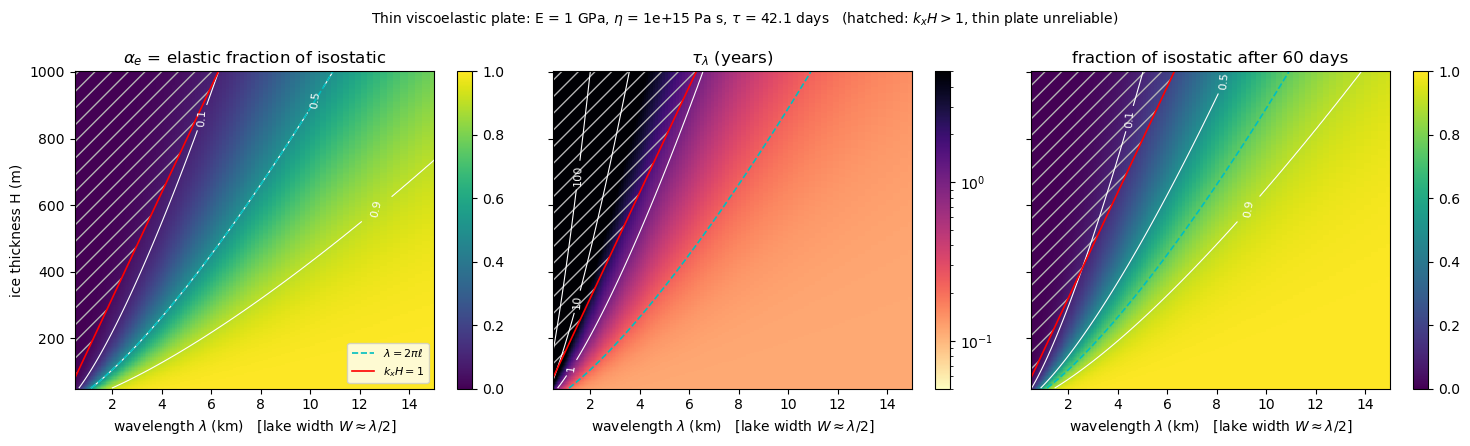

In [44]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

# --- parameters ---
E      = 1e9        # Young's modulus (Pa)
nu     = 0.3        # Poisson's ratio
eta    = 1e15       # viscosity (Pa s)
rho_sw = 1028.0     # seawater density (kg/m^3)
g      = 9.81       # gravity (m/s^2)
q_hat  = 1.0        # load amplitude (Pa); results are relative to q_hat/k
t_melt = 60.0       # melt-season length (days), for the third panel

k   = rho_sw * g
tau = 4 * eta * (1 - nu**2) / E          # Maxwell time (s), independent of H
day, year = 86400.0, 365.25 * 86400.0


def w_hat(t, kx, q_hat, k, D, tau):
    """
    Amplitude of the cos(kx x) deflection mode as a function of time.

    The load q_hat cos(kx x) is switched on suddenly at time zero and held constant.
    t : time(s) since the load was applied (s); scalar or array, t >= 0.

    Returns (w, tau_l):
      w     : amplitude at each t; w = elastic value at t = 0, -> q_hat/k as t -> inf
      tau_l : relaxation time of this mode (s)
    """
    ell   = (D / k) ** 0.25
    w_iso = q_hat / k                          # isostatic (t -> infinity)
    w_el  = q_hat / (D * kx**4 + k)            # elastic jump (t = 0+)
    tau_l = tau * (1 + (kx * ell) ** 4)        # relaxation time of this mode
    return w_iso + (w_el - w_iso) * np.exp(-t / tau_l), tau_l


# --- grid in (wavelength, thickness) ---
lam_km = np.logspace(np.log10(0.1), np.log10(50), 300)   # wavelength (km)
H      = np.linspace(50, 1000, 250)                      # ice thickness (m)
LAM, HH = np.meshgrid(lam_km * 1e3, H)                   # shape (len(H), len(lam))

KX  = 2 * np.pi / LAM
DD  = E * HH**3 / (12 * (1 - nu**2))
ELL = (DD / k) ** 0.25

w0,     tau_l = w_hat(0.0,          KX, q_hat, k, DD, tau)   # elastic response
w_seas, _     = w_hat(t_melt * day, KX, q_hat, k, DD, tau)   # after one melt season

alpha_e   = w0 / (q_hat / k)        # instant (elastic) fraction of isostatic
frac_seas = w_seas / (q_hat / k)    # fraction of isostatic after t_melt
kxH       = KX * HH                 # thin-plate validity: need kxH << 1

# --- plot ---
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)

panels = [
    (alpha_e,      dict(vmin=0, vmax=1, cmap="viridis"),
     r"$\alpha_e$ = elastic fraction of isostatic", [0.1, 0.5, 0.9]),
    (tau_l / year, dict(norm=LogNorm(5e-2, 0.5e1), cmap="magma_r"),
     r"$\tau_\lambda$ (years)", [0.1, 1, 10, 100]),
    (frac_seas,    dict(vmin=0, vmax=1, cmap="viridis"),
     fr"fraction of isostatic after {t_melt:.0f} days", [0.1, 0.5, 0.9]),
]

for ax, (Z, kw, title, levels) in zip(axes, panels):
    pc = ax.pcolormesh(lam_km, H, Z, shading="auto", **kw)
    fig.colorbar(pc, ax=ax)
    cs = ax.contour(lam_km, H, Z, levels=levels, colors="w", linewidths=0.8)
    ax.clabel(cs, fmt="%g", fontsize=8)

    # flexural crossover lambda = 2*pi*ell(H)
    ax.plot(2 * np.pi * ELL[:, 0] / 1e3, H, "c--", lw=1.2, label=r"$\lambda = 2\pi\ell$")
    # thin-plate validity limit kxH = 1 (left of this line the beam is unreliable)
    ax.plot(2 * np.pi * H / 1e3, H, "r-", lw=1.2, label=r"$k_xH = 1$")
    ax.fill_betweenx(H, lam_km[0], 2 * np.pi * H / 1e3,
                     facecolor="none", edgecolor="0.7", hatch="//", lw=0)

    # ax.set_xscale("log")
    ax.set_xlim(0.5, 15)
    ax.set_xlabel(r"wavelength $\lambda$ (km)   [lake width $W \approx \lambda/2$]")
    ax.set_title(title)

axes[0].set_ylabel("ice thickness H (m)")
axes[0].legend(fontsize=8, loc="lower right")
fig.suptitle(fr"Thin viscoelastic plate: E = {E/1e9:g} GPa, $\eta$ = {eta:.0e} Pa s, "
             fr"$\tau$ = {tau/day:.1f} days   (hatched: $k_xH > 1$, thin plate unreliable)",
             fontsize=10)
plt.tight_layout()
plt.show()

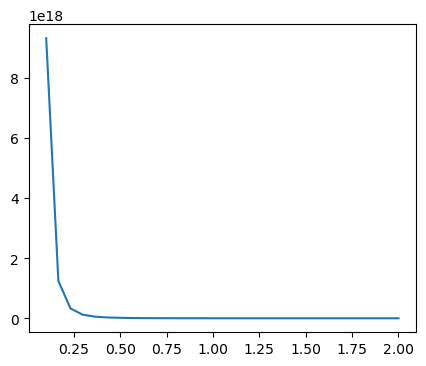

In [12]:
# Right: relaxation time against wavelength (reuses w_hat's tau_l output)
lam = np.linspace(0.1, 2, 30)          
_, tau_l = w_hat(0.0, 2 * np.pi / lam, q_hat, k, D, tau)
fig, ax2 = plt.subplots(1, 1, figsize=(5, 4))
ax2.plot(lam, tau_l / day)
# ax2.axvline(2 * np.pi * ell / 1e3, color="grey", ls="--", lw=0.8, label=r"$\lambda = 2\pi\ell$")
# ax2.axhline(365, color="grey", ls=":", lw=0.8, label="1 year")
# ax2.set_xlabel(r"wavelength $\lambda$ (km)")
# ax2.set_ylabel(r"$\tau_\lambda$ (days)")
# ax2.set_title(r"$\tau_\lambda = \tau\,[1 + (k_x\ell)^4]$")
# ax2.legend(fontsize=8)


Text(0, 0.5, 'Flexural length (m)')

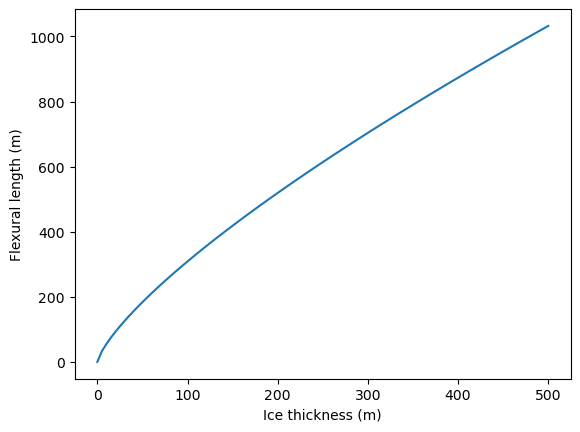

In [18]:
H = np.linspace(0, 500, 100)

D   = E * H**3 / (12 * (1 - nu**2))      # flexural rigidity (N m)

ell   = (D / k) ** 0.25

plt.plot(H, ell)
plt.xlabel("Ice thickness (m)")
plt.ylabel("Flexural length (m)")